# Waimea WaveCast — Kiểm thử Near Real-Time mỗi 30 phút

**Thứ tự:** CDIP 106 (quan trắc) → NOAA 51201 (quan trắc dự phòng) → Open-Meteo (mô hình/dự báo). Notebook luôn kiểm tra cả ba nguồn để so sánh timestamp.

**Những thay đổi trong phiên bản 30 phút:**

1. Polling **30 phút/lần** (`POLL_INTERVAL_SECONDS = 1800`) thay vì 2 phút. Có chế độ căn lịch ở **phút :28 và :58 mỗi giờ theo UTC**, nhằm kiểm tra sau mốc quan trắc NOAA thường thấy tại phút :26 và :56. Các mốc dữ liệu/công bố không được đảm bảo cố định.
2. Có thể chạy thử ngay một lần. Chế độ theo dõi 24 giờ **tắt mặc định** để lệnh *Run All* không làm kernel treo lâu; bật bằng `MONITOR_ENABLED = True` tại cell theo dõi.
3. Open-Meteo lấy **24 giờ trước và 24 giờ dự báo**. CSV xuất có thêm giờ UTC, Việt Nam (UTC+7), Hawaii (UTC−10), và nhãn *PAST / CURRENT_HOUR / FORECAST*.
4. Hiển thị `fetched_at_utc` (giờ gọi), `data_time_utc` (mốc có hiệu lực của dữ liệu) và `age_minutes` (độ tuổi timestamp). Với Open-Meteo, giờ tương lai là **dự báo**, không phải quan trắc đã xảy ra.
5. Lưu `poll_history.csv` và `first_seen.csv` trong thư mục `waimea_realtime_test`.

**Lưu ý:** gọi 30 phút/lần **không đảm bảo** nguồn CDIP/NOAA phát hành dữ liệu ngay ở phút đó; nếu không có bản ghi mới, bảng sẽ hiện `SAME`.

Nguồn: [CDIP NDAR](https://cdip.ucsd.edu/data_access/ndar.cdip), [NOAA 51201](https://www.ndbc.noaa.gov/data/realtime2/51201.txt), [Open-Meteo Marine API](https://open-meteo.com/en/docs/marine-weather-api).

In [1]:
# Chạy cell này một lần, sau đó chọn lại kernel nếu môi trường yêu cầu.
%pip install -q requests pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. Cấu hình

- **Lịch:** một lần gọi thử ngay khi chạy cell 7; nếu bật monitor, các lần tiếp theo sẽ cách nhau **30 phút**.
- `ALIGN_TO_BUOY_CYCLE = True`: lần theo dõi tiếp theo căn vào **:28 và :58 UTC**; mục đích là thử truy cập ngay sau mốc phao thường thấy **:26 / :56 UTC**, không phải cam kết nhà cung cấp công bố đúng phút.
- Đổi `ALIGN_TO_BUOY_CYCLE = False` nếu chỉ muốn mỗi 30 phút tính từ lần chạy trước, không căn lịch.
- `MONITOR_CYCLES = 48`: tối đa 48 lần gọi, tương đương gần 24 giờ theo dõi; có thể dừng bằng **Interrupt Kernel**.
- Open-Meteo `past_hours=24`, `forecast_hours=24`; file CSV có giờ Việt Nam và Hawaii.
- `MAX_OBSERVATION_AGE_MIN = 120` để đánh dấu phao đã cũ, **không phải** một SLA độ trễ.


In [2]:
from __future__ import annotations

import io
import re
import time
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd
import requests
from IPython.display import display

# Cấu hình Waimea Bay
CDIP_STATION = "106"
NOAA_STATION = "51201"
LAT, LON = 21.671, -158.118
MAX_OBSERVATION_AGE_MIN = 120
REQUEST_TIMEOUT_SECONDS = 25

# Polling: chỉ dùng thử nghiệm, không phải cron/scheduler production.
MONITOR_ENABLED = False
MONITOR_CYCLES = 48              # 48 lần ~ 24 giờ kiểm tra (mỗi 30 phút)
POLL_INTERVAL_SECONDS = 1800      # 30 phút
ALIGN_TO_BUOY_CYCLE = True        # Theo lịch :28, :58 phút mỗi giờ UTC
BUOY_POLL_OFFSET_MINUTE = 28      # 28 hoặc 58; chỉ là thời điểm gọi dự kiến
OPEN_METEO_PAST_HOURS = 24
OPEN_METEO_FORECAST_HOURS = 24

OUTPUT = Path("waimea_realtime_test")
OUTPUT.mkdir(exist_ok=True)

CDIP_NDAR_URL = f"https://cdip.ucsd.edu/data_access/ndar.cdip?{CDIP_STATION}+pm+1+h"
CDIP_JUSTDAR_URL = f"https://cdip.ucsd.edu/data_access/justdar.cdip?{CDIP_STATION}+pm+1"
NOAA_URL = f"https://www.ndbc.noaa.gov/data/realtime2/{NOAA_STATION}.txt"
OPEN_METEO_URL = "https://marine-api.open-meteo.com/v1/marine"

SESSION = requests.Session()
SESSION.headers.update({"User-Agent": "WaimeaWaveCast-educational-api-test/1.0", "Accept": "text/plain, application/json, */*"})

print("CDIP:", CDIP_NDAR_URL)
print("NOAA:", NOAA_URL)
print("Open-Meteo:", OPEN_METEO_URL)

CDIP: https://cdip.ucsd.edu/data_access/ndar.cdip?106+pm+1+h
NOAA: https://www.ndbc.noaa.gov/data/realtime2/51201.txt
Open-Meteo: https://marine-api.open-meteo.com/v1/marine


## 2. Hàm xử lý chung

`http_get` thực hiện một request có timeout. Để dễ so sánh độ trễ, notebook không tự ẩn nhiều lần retry. Các lỗi được ghi vào bảng kết quả; thông số **`age_minutes` đo thời gian từ timestamp bản ghi tới lúc nhận API**, không phải thời gian truyền/công bố thực sự.

In [3]:
def utc_now():
    return pd.Timestamp.now(tz="UTC")


def iso_utc(value):
    if value is None or pd.isna(value):
        return None
    return pd.Timestamp(value).tz_convert("UTC").isoformat()


def valid_number(value, lower=None, upper=None):
    try:
        if value is None or str(value).strip().upper() in {"", "MM", "NAN", "NONE", "NULL"}:
            return None
        f = float(value)
        if not pd.notna(f):
            return None
        if (lower is not None and f < lower) or (upper is not None and f > upper):
            return None
        return f
    except (ValueError, TypeError):
        return None


def age_minutes(when, now=None):
    if when is None or pd.isna(when):
        return None
    now = now if now is not None else utc_now()
    return round((now - pd.Timestamp(when)).total_seconds() / 60, 2)


def http_get(url, params=None):
    start = time.perf_counter()
    response = SESSION.get(url, params=params, timeout=REQUEST_TIMEOUT_SECONDS)
    elapsed_ms = round((time.perf_counter() - start) * 1000)
    fetched_at = utc_now()
    response.raise_for_status()
    return response, fetched_at, elapsed_ms


def row_template(source, data_type="observation"):
    return {
        "source": source,
        "data_type": data_type,
        "status": "error",
        "fetched_at_utc": None,
        "data_time_utc": None,
        "age_minutes": None,
        "wave_height_m": None,
        "wave_period_s": None,
        "wave_direction_deg": None,
        "sea_surface_temperature_c": None,
        "request_ms": None,
        "endpoint": None,
        "note": None,
    }


def filled_row(source, data_type, fetched_at, data_time, elapsed_ms, endpoint, **values):
    r = row_template(source, data_type)
    r.update({
        "status": "ok",
        "fetched_at_utc": iso_utc(fetched_at),
        "data_time_utc": iso_utc(data_time),
        "age_minutes": age_minutes(data_time, fetched_at),
        "request_ms": elapsed_ms,
        "endpoint": endpoint,
    })
    r.update(values)
    return r


def to_local_time(text, timezone_name):
    """Chuyển ISO UTC sang giờ địa phương, an toàn với None/NaN/NaT."""
    if text is None or pd.isna(text) or not str(text).strip():
        return None
    stamp = pd.to_datetime(text, utc=True, errors="coerce")
    if pd.isna(stamp):
        return None
    return stamp.tz_convert(timezone_name).strftime("%Y-%m-%d %H:%M:%S %Z")

## 3. Adapter CDIP 106 — quan trắc ưu tiên

Dùng **NDAR định dạng `pm`**, không cần `netCDF4`. Nếu NDAR báo lỗi hoặc không có hàng hợp lệ, notebook thử `justdar` và ghi lại bản phản hồi vào file debug.

Trong định dạng `pm` cổ điển, 5 cột đầu là `year month day hour minute`, cột thứ 6 là **Hs (m)**, cột thứ 7 **Tp (s)**, cột thứ 8 **Dp (°)**. Nếu nguồn thay đổi định dạng, parser báo lỗi thay vì tự gán sai dữ liệu. Dữ liệu thời gian của CDIP có thể là thời điểm **bắt đầu kỳ quan trắc**.

In [4]:
def parse_cdip_pm(text):
    if not text.strip() or text.lstrip().lower().startswith(("<!doctype", "<html")):
        raise ValueError("CDIP trả HTML/rỗng thay vì dữ liệu PM")

    rows = []
    for line in text.splitlines():
        fields = re.split(r"\s+", line.strip())
        if len(fields) < 6 or not re.fullmatch(r"(?:19|20)\d{2}", fields[0]):
            continue
        try:
            parts = [int(v) for v in fields[:5]]
            stamp = pd.Timestamp(datetime(*parts, tzinfo=timezone.utc))
        except (ValueError, TypeError):
            continue
        # Kiểm tra miền thời gian trước khi đọc các cột vật lý.
        if stamp > utc_now() + pd.Timedelta(minutes=10) or stamp.year < 1990:
            continue
        h = valid_number(fields[5], lower=0, upper=40)
        if h is None:
            continue
        rows.append({
            "timestamp": stamp,
            "wave_height_m": h,
            "wave_period_s": valid_number(fields[6], lower=0.1, upper=100) if len(fields) > 6 else None,
            "wave_direction_deg": valid_number(fields[7], lower=0, upper=360) if len(fields) > 7 else None,
        })
    if not rows:
        raise ValueError("Không tìm thấy bản ghi PM hợp lệ (YYYY MM DD HH mm Hs ...)")
    return max(rows, key=lambda r: r["timestamp"]), len(rows)


def fetch_cdip():
    errors = []
    for label, url in [("NDAR", CDIP_NDAR_URL), ("Justdar", CDIP_JUSTDAR_URL)]:
        try:
            response, fetched, elapsed = http_get(url)
            (OUTPUT / "cdip_last_response.txt").write_text(response.text[:30000], encoding="utf-8")
            sample, count = parse_cdip_pm(response.text)
            return filled_row(
                "CDIP 106", "observation", fetched, sample["timestamp"], elapsed, response.url,
                wave_height_m=sample["wave_height_m"],
                wave_period_s=sample["wave_period_s"],
                wave_direction_deg=sample["wave_direction_deg"],
                note=f"{label}: đọc {count} bản ghi PM; timestamp có thể là đầu kỳ đo",
            )
        except (requests.RequestException, ValueError, UnicodeError, OSError) as exc:
            errors.append(f"{label}: {type(exc).__name__}: {str(exc)[:220]}")
    r = row_template("CDIP 106")
    r["note"] = " | ".join(errors)
    return r

## 4. Adapter NOAA 51201 — quan trắc dự phòng

NOAA `/data/realtime2/51201.txt` có 2 dòng header, tiếp theo là những hàng dữ liệu. Đọc tên cột từ header thật để không phụ thuộc vào vị trí cố định của các cột `WVHT`, `DPD`, `MWD`, `WTMP`. `MM` là thiếu dữ liệu.

In [5]:
def parse_noaa_txt(text):
    lines = text.splitlines()
    if len(lines) < 3 or not lines[0].lstrip().startswith("#"):
        raise ValueError("NOAA TXT không có header hợp lệ")

    columns = lines[0].lstrip("# ").split()
    records = []
    for line in lines[2:]:
        parts = line.split()
        if len(parts) != len(columns):
            continue
        rec = dict(zip(columns, parts))
        try:
            year = int(rec.get("YY", rec.get("YYYY")))
            if year < 100:
                year += 2000 if year < 70 else 1900
            stamp = pd.Timestamp(datetime(
                year, int(rec["MM"]), int(rec["DD"]),
                int(rec["hh"]), int(rec["mm"]), tzinfo=timezone.utc
            ))
        except (ValueError, KeyError, TypeError):
            continue
        h = valid_number(rec.get("WVHT"), lower=0, upper=40)
        if h is None:
            continue
        records.append({
            "timestamp": stamp,
            "wave_height_m": h,
            "wave_period_s": valid_number(rec.get("DPD"), lower=0.1, upper=100),
            "wave_direction_deg": valid_number(rec.get("MWD"), lower=0, upper=360),
            "sea_surface_temperature_c": valid_number(rec.get("WTMP"), lower=-3, upper=45),
        })
    if not records:
        raise ValueError("Không tìm thấy bản ghi NOAA có WVHT hợp lệ")
    return max(records, key=lambda r: r["timestamp"]), len(records)


def fetch_noaa():
    try:
        response, fetched, elapsed = http_get(NOAA_URL)
        sample, count = parse_noaa_txt(response.text)
        return filled_row(
            "NOAA 51201", "observation", fetched, sample["timestamp"], elapsed, response.url,
            wave_height_m=sample["wave_height_m"],
            wave_period_s=sample["wave_period_s"],
            wave_direction_deg=sample["wave_direction_deg"],
            sea_surface_temperature_c=sample["sea_surface_temperature_c"],
            note=f"Đọc {count} hàng có WVHT hợp lệ trong TXT",
        )
    except (requests.RequestException, ValueError, UnicodeError, OSError) as exc:
        r = row_template("NOAA 51201")
        r["note"] = f"{type(exc).__name__}: {str(exc)[:300]}"
        return r

## 5. Adapter Open-Meteo — giờ Việt Nam và 24 giờ dự báo

Open-Meteo trả **dữ liệu mô hình** theo thời gian UTC (theo cấu hình `timezone="UTC"`). Notebook lấy **24 giờ lịch sử mô hình và 24 giờ dự báo** qua `past_hours` / `forecast_hours`, rồi xuất `open_meteo_hourly.csv` với cả giờ Việt Nam và Hawaii. Ngày giờ quá khứ của mô hình không được coi là phép đo tại phao.

Đặc biệt, CSV có một mốc `13:00 UTC` thì đó là **20:00 giờ Việt Nam**, không phải dữ liệu mới nhất chỉ đến 13:00 Việt Nam.

In [6]:
OPEN_METEO_VARIABLES = (
    "wave_height,wave_period,wave_direction,"
    "swell_wave_height,sea_surface_temperature"
)


def enrich_open_meteo_times(frame, fetched_at):
    """Giữ cột time gốc của API và thêm thông tin ngày giờ, không coi forecast là observation."""
    frame = frame.copy()
    frame["time_utc"] = pd.to_datetime(frame["time"], utc=True)
    frame["time_vietnam"] = frame["time_utc"].dt.tz_convert("Asia/Ho_Chi_Minh").dt.strftime("%Y-%m-%d %H:%M %z")
    frame["time_hawaii"] = frame["time_utc"].dt.tz_convert("Pacific/Honolulu").dt.strftime("%Y-%m-%d %H:%M %z")
    current_hour = fetched_at.floor("h")
    frame["time_type"] = frame["time_utc"].map(
        lambda t: "PAST" if t < current_hour else ("CURRENT_HOUR" if t == current_hour else "FORECAST")
    )
    frame["fetched_at_utc"] = fetched_at.isoformat()
    return frame


def fetch_open_meteo():
    params = {
        "latitude": LAT,
        "longitude": LON,
        "current": OPEN_METEO_VARIABLES,
        "hourly": OPEN_METEO_VARIABLES,
        "past_hours": OPEN_METEO_PAST_HOURS,
        "forecast_hours": OPEN_METEO_FORECAST_HOURS,
        "timezone": "UTC",
        "cell_selection": "sea",
    }
    try:
        response, fetched, elapsed = http_get(OPEN_METEO_URL, params=params)
        data = response.json()
        if data.get("error"):
            raise ValueError(data.get("reason", "Open-Meteo trả lỗi JSON"))
        current = data.get("current") or {}
        if not current.get("time"):
            raise ValueError("Không có current.time trong phản hồi Open-Meteo")
        time_utc = pd.Timestamp(current["time"], tz="UTC")
        h = valid_number(current.get("wave_height"), lower=0, upper=40)
        if h is None:
            raise ValueError("Open-Meteo không trả current.wave_height hợp lệ")

        hourly = data.get("hourly") or {}
        if hourly.get("time"):
            frame = enrich_open_meteo_times(pd.DataFrame(hourly), fetched)
            frame.to_csv(OUTPUT / "open_meteo_hourly.csv", index=False)
            print(f"Open-Meteo: đã lưu {len(frame)} mốc giờ vào open_meteo_hourly.csv")
            print("Đầu dải (VN):", frame.iloc[0]["time_vietnam"])
            print("Cuối dải (VN):", frame.iloc[-1]["time_vietnam"])

        return filled_row(
            "Open-Meteo", "model", fetched, time_utc, elapsed, response.url,
            wave_height_m=h,
            wave_period_s=valid_number(current.get("wave_period"), lower=0.1, upper=100),
            wave_direction_deg=valid_number(current.get("wave_direction"), lower=0, upper=360),
            sea_surface_temperature_c=valid_number(current.get("sea_surface_temperature"), lower=-3, upper=45),
            note="Mô hình current; hourly CSV chứa 24 giờ trước + 24 giờ dự báo (không phải số đo)",
        )
    except (requests.RequestException, ValueError, KeyError, TypeError) as exc:
        r = row_template("Open-Meteo", "model")
        r["note"] = f"{type(exc).__name__}: {str(exc)[:300]}"
        return r


## 6. Gọi từng nguồn, chọn fallback và theo dõi bản ghi mới

Logic chọn nguồn:

- CDIP `ok` + dữ liệu không quá ngưỡng cũ → ưu tiên **CDIP**; nếu NOAA có timestamp mới hơn CDIP ít nhất 30 phút, tạm chọn **NOAA** (heuristic cần kiểm tra ý nghĩa timestamp).
- Nếu không → NOAA `ok` + đủ mới → chọn **NOAA**.
- Nếu không → lấy **Open-Meteo**, gắn nhãn `MODEL (NOT OBSERVED)`.
- Nếu cả ba lỗi → báo **NO DATA**.

Đồng thời, bảng so sánh **vẫn hiển thị cả CDIP và NOAA** để bạn kiểm tra nguồn nào xuất hiện bản ghi sớm hơn. `first_seen_utc` là thời điểm notebook lần đầu phát hiện bản ghi trong **phiên thử hiện tại**, không phải thời điểm nhà cung cấp công bố. Dữ liệu còn lại không được tự điền bằng giá trị mô hình.

In [7]:
HISTORY = []
SEEN_TIMESTAMPS = {}      # So sánh thay đổi giữa các lần poll trong phiên notebook
FIRST_SEEN_LOG = []


def is_recent_observation(row):
    return (
        row["status"] == "ok"
        and row["data_type"] == "observation"
        and row["age_minutes"] is not None
        and -5 <= row["age_minutes"] <= MAX_OBSERVATION_AGE_MIN
        and row["wave_height_m"] is not None
    )


def choose_source(rows):
    by_name = {r["source"]: r for r in rows}
    cdip = by_name["CDIP 106"]
    noaa = by_name["NOAA 51201"]
    # Do CDIP/NOAA có thể gắn nhãn timestamp ở các mốc khác nhau của kỳ đo,
    # chỉ ghi đè ưu tiên CDIP khi NOAA mới hơn RÕ RỆT (>= 30 phút).
    # Đây là heuristic phục vụ thử nghiệm, không phải khẳng định hai kỳ đo tương đương.
    if is_recent_observation(cdip) and is_recent_observation(noaa):
        if cdip["age_minutes"] - noaa["age_minutes"] >= 30:
            return "NOAA 51201", "OBSERVATION"
        return "CDIP 106", "OBSERVATION"
    if is_recent_observation(cdip):
        return "CDIP 106", "OBSERVATION"
    if is_recent_observation(noaa):
        return "NOAA 51201", "OBSERVATION"
    if by_name["Open-Meteo"]["status"] == "ok":
        return "Open-Meteo", "MODEL (NOT OBSERVED)"
    return None, "NO DATA"


def run_probe():
    started = utc_now()
    print(f"\n=== KIỂM TRA: {started.strftime('%Y-%m-%d %H:%M:%S UTC')} ===")
    rows = [fetch_cdip(), fetch_noaa(), fetch_open_meteo()]
    chosen, chosen_type = choose_source(rows)
    for row in rows:
        source = row["source"]
        current_stamp = row["data_time_utc"] if row["status"] == "ok" else None
        previous_stamp = SEEN_TIMESTAMPS.get(source)
        if current_stamp:
            if source not in SEEN_TIMESTAMPS:
                status_change = "INITIAL"
            elif previous_stamp != current_stamp:
                status_change = "NEW"
            else:
                status_change = "SAME"
            if status_change in ("INITIAL", "NEW"):
                FIRST_SEEN_LOG.append({
                    "source": source,
                    "data_time_utc": current_stamp,
                    "first_seen_utc": row["fetched_at_utc"],
                    "status_change": status_change,
                    "type": row["data_type"],
                })
            SEEN_TIMESTAMPS[source] = current_stamp
        else:
            status_change = "ERROR"
        row["poll_started_utc"] = iso_utc(started)
        row["change"] = status_change
        row["selected"] = row["source"] == chosen
        HISTORY.append(row.copy())

    df = pd.DataFrame(rows)
    columns = ["source", "data_type", "status", "change", "data_time_utc",
               "fetched_at_utc", "age_minutes", "wave_height_m", "wave_period_s",
               "wave_direction_deg", "sea_surface_temperature_c", "request_ms", "selected"]
    display(df[columns])
    print("Nguồn được chọn:", chosen or "Không có", "|", chosen_type)
    if chosen_type == "MODEL (NOT OBSERVED)":
        print("CẢNH BÁO: đây là dự báo/mô hình, KHÔNG phải quan trắc thực tế!")
    for row in rows:
        if row["status"] != "ok":
            print("Lỗi", row["source"], ":", row["note"])
    return df

## 7. Kiểm tra ngay — chạy một lần

Chạy cell dưới để gọi **CDIP, NOAA và Open-Meteo** ngay lập tức. Thời gian `data_time_utc` của Open-Meteo là **thời điểm hiệu lực mô hình**, còn CDIP/NOAA là **timestamp quan trắc**. Hiển thị thêm giờ Việt Nam/Hawaii. File Open-Meteo lấy 24 giờ trước và 24 giờ dự báo.

In [8]:
latest_results = run_probe()

# Hiển thị thêm giờ Việt Nam và giờ Hawaii để tránh hiểu nhầm ngày UTC.
time_comparison = latest_results[["source", "data_time_utc", "age_minutes", "change"]].copy()
time_comparison["giờ_Việt_Nam"] = time_comparison["data_time_utc"].map(
    lambda s: to_local_time(s, "Asia/Ho_Chi_Minh")
)
time_comparison["giờ_Hawaii"] = time_comparison["data_time_utc"].map(
    lambda s: to_local_time(s, "Pacific/Honolulu")
)
display(time_comparison)


=== KIỂM TRA: 2026-11-01 05:42:48 UTC ===
Open-Meteo: đã lưu 48 mốc giờ vào open_meteo_hourly.csv
Đầu dải (VN): 2026-10-31 12:00 +0700
Cuối dải (VN): 2026-11-02 11:00 +0700


,source,data_type,status,change,data_time_utc,fetched_at_utc,age_minutes,wave_height_m,wave_period_s,wave_direction_deg,sea_surface_temperature_c,request_ms,selected
0,CDIP 106,observation,error,ERROR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
1,NOAA 51201,observation,ok,INITIAL,2026-11-01T04:56:00+00:00,2026-11-01T05:42:50.990918+00:00,46.85,1.70,20.00,309.0,26.3,592.0,True
2,Open-Meteo,model,ok,INITIAL,2026-11-01T05:30:00+00:00,2026-11-01T05:42:52.745635+00:00,12.88,1.58,12.75,5.0,26.5,1705.0,False


Nguồn được chọn: NOAA 51201 | OBSERVATION
Lỗi CDIP 106 : NDAR: HTTPError: 403 Client Error: Forbidden for url: https://cdip.ucsd.edu/data_access/ndar.cdip?106+pm+1+h | Justdar: HTTPError: 403 Client Error: Forbidden for url: https://cdip.ucsd.edu/data_access/justdar.cdip?106+pm+1


,source,data_time_utc,age_minutes,change,giờ_Việt_Nam,giờ_Hawaii
0,CDIP 106,NaN,NaN,ERROR,NaN,NaN
1,NOAA 51201,2026-11-01T04:56:00+00:00,46.85,INITIAL,2026-11-01 11:56:00 +07,2026-10-31 18:56:00 HST
2,Open-Meteo,2026-11-01T05:30:00+00:00,12.88,INITIAL,2026-11-01 12:30:00 +07,2026-10-31 19:30:00 HST


### Kiểm tra dải giờ Open-Meteo trong file CSV

Cell sau đọc CSV mới tạo và hiển thị giờ **UTC / Việt Nam / Hawaii**. Những hàng thuộc `FORECAST` là thời điểm tương lai, không phải bản ghi quan trắc có sẵn từ phao.

In [9]:
open_meteo_csv = OUTPUT / "open_meteo_hourly.csv"
if open_meteo_csv.exists():
    meteo_preview = pd.read_csv(open_meteo_csv)
    print("Tổng số giờ trả về:", len(meteo_preview))
    print("Phân loại các mốc giờ:")
    display(meteo_preview["time_type"].value_counts().rename_axis("Loại giờ").to_frame("Số bản ghi"))
    print("5 mốc đầu:")
    display(meteo_preview[["time_utc", "time_vietnam", "time_hawaii", "time_type", "wave_height"]].head(5))
    print("10 mốc cuối:")
    display(meteo_preview[["time_utc", "time_vietnam", "time_hawaii", "time_type", "wave_height"]].tail(10))
else:
    print("Chưa có file; cần chạy cell Kiểm tra ngay trước.")

Tổng số giờ trả về: 48
Phân loại các mốc giờ:


,Số bản ghi
Loại giờ,
PAST,24
FORECAST,23
CURRENT_HOUR,1


5 mốc đầu:


,time_utc,time_vietnam,time_hawaii,time_type,wave_height
0,2026-10-31 05:00:00+00:00,2026-10-31 12:00 +0700,2026-10-30 19:00 -1000,PAST,1.72
1,2026-10-31 06:00:00+00:00,2026-10-31 13:00 +0700,2026-10-30 20:00 -1000,PAST,1.70
2,2026-10-31 07:00:00+00:00,2026-10-31 14:00 +0700,2026-10-30 21:00 -1000,PAST,1.66
3,2026-10-31 08:00:00+00:00,2026-10-31 15:00 +0700,2026-10-30 22:00 -1000,PAST,1.64
4,2026-10-31 09:00:00+00:00,2026-10-31 16:00 +0700,2026-10-30 23:00 -1000,PAST,1.60


10 mốc cuối:


,time_utc,time_vietnam,time_hawaii,time_type,wave_height
38,2026-11-01 19:00:00+00:00,2026-11-02 02:00 +0700,2026-11-01 09:00 -1000,FORECAST,2.12
39,2026-11-01 20:00:00+00:00,2026-11-02 03:00 +0700,2026-11-01 10:00 -1000,FORECAST,2.22
40,2026-11-01 21:00:00+00:00,2026-11-02 04:00 +0700,2026-11-01 11:00 -1000,FORECAST,2.34
41,2026-11-01 22:00:00+00:00,2026-11-02 05:00 +0700,2026-11-01 12:00 -1000,FORECAST,2.44
42,2026-11-01 23:00:00+00:00,2026-11-02 06:00 +0700,2026-11-01 13:00 -1000,FORECAST,2.56
43,2026-11-02 00:00:00+00:00,2026-11-02 07:00 +0700,2026-11-01 14:00 -1000,FORECAST,2.66
44,2026-11-02 01:00:00+00:00,2026-11-02 08:00 +0700,2026-11-01 15:00 -1000,FORECAST,2.70
45,2026-11-02 02:00:00+00:00,2026-11-02 09:00 +0700,2026-11-01 16:00 -1000,FORECAST,2.76
46,2026-11-02 03:00:00+00:00,2026-11-02 10:00 +0700,2026-11-01 17:00 -1000,FORECAST,2.80
47,2026-11-02 04:00:00+00:00,2026-11-02 11:00 +0700,2026-11-01 18:00 -1000,FORECAST,2.82


## 8. Theo dõi tự động **mỗi 30 phút** (tùy chọn)

Đặt `MONITOR_ENABLED = True` ngay trong cell bên dưới rồi chạy **cell này**. Mặc định `MONITOR_CYCLES=48`.

- **Căn lịch bật:** lần đầu gọi ngay, các lần tiếp theo tại phút **:28 / :58 UTC**. Hai mốc này cách nhau 30 phút. Đây là cách thử nghiệm dựa trên timestamp NOAA thường thấy, không phải lịch phát hành được bảo đảm.
- **Căn lịch tắt:** các lần cách nhau khoảng 30 phút tính từ lúc bắt đầu vòng trước; quá trình HTTP có thể làm chênh lệch vài giây.
- Mỗi vòng gọi các endpoint công khai **một lần cho mỗi nguồn** (CDIP có thể thử NDAR và Justdar khi lỗi), ghi `poll_history.csv`, `first_seen.csv`.
- Trong lúc notebook đang theo dõi, kernel sẽ đợi đến mốc tiếp theo. Nhấn **Interrupt Kernel** để dừng và giữ các CSV đã ghi.
- Các mốc Open-Meteo tương lai là dự báo, **không phải quan trắc được cập nhật mỗi 30 phút**.

In [10]:
# Bật True khi muốn theo dõi 30 phút/lần; False = không chạy nền, không chờ.
MONITOR_ENABLED = False


def next_aligned_poll(now, offset_minute=BUOY_POLL_OFFSET_MINUTE):
    """Lịch 30 phút một lần: :28/:58 UTC (nếu offset_minute=28)."""
    if not 0 <= offset_minute < 30:
        raise ValueError("BUOY_POLL_OFFSET_MINUTE phải trong khoảng 0..29")
    now = pd.Timestamp(now).tz_convert("UTC")
    slot = now.floor("h") + pd.Timedelta(minutes=offset_minute)
    while slot <= now:
        slot += pd.Timedelta(minutes=30)
    return slot


if MONITOR_ENABLED:
    if MONITOR_CYCLES < 1 or POLL_INTERVAL_SECONDS < 60:
        raise ValueError("Cần ít nhất 1 chu kỳ và khoảng chờ tối thiểu 60 giây")
    print(f"Đang theo dõi {MONITOR_CYCLES} vòng, khoảng cách {POLL_INTERVAL_SECONDS // 60} phút")
    try:
        for cycle in range(MONITOR_CYCLES):
            started = utc_now()
            print(f"\n===== VÒNG {cycle + 1}/{MONITOR_CYCLES} =====")
            run_probe()
            pd.DataFrame(HISTORY).to_csv(OUTPUT / "poll_history.csv", index=False)
            pd.DataFrame(FIRST_SEEN_LOG).to_csv(OUTPUT / "first_seen.csv", index=False)
            if cycle + 1 < MONITOR_CYCLES:
                if ALIGN_TO_BUOY_CYCLE:
                    target = next_aligned_poll(utc_now())
                else:
                    target = started + pd.Timedelta(seconds=POLL_INTERVAL_SECONDS)
                    if target <= utc_now():
                        target = utc_now() + pd.Timedelta(seconds=POLL_INTERVAL_SECONDS)
                waiting_seconds = max(0, (target - utc_now()).total_seconds())
                print("Lần kiểm tra kế tiếp (UTC):", target.strftime("%Y-%m-%d %H:%M:%S"))
                print("Lần kiểm tra kế tiếp (VN): ", target.tz_convert("Asia/Ho_Chi_Minh").strftime("%Y-%m-%d %H:%M:%S"))
                time.sleep(waiting_seconds)
    except KeyboardInterrupt:
        print("Đã dừng theo dõi; các CSV đã ghi vẫn giữ nguyên")
else:
    print("Theo dõi 30 phút/lần đang tắt. Đặt MONITOR_ENABLED=True và chạy lại cell này nếu muốn bật.")


Theo dõi 30 phút/lần đang tắt. Đặt MONITOR_ENABLED=True và chạy lại cell này nếu muốn bật.


## 9. Xuất CSV và đối chiếu thời gian

- `poll_history.csv`: log mỗi lần gọi API; mỗi nguồn một dòng.
- `first_seen.csv`: thời điểm notebook **lần đầu nhìn thấy timestamp**, không phải thời điểm xuất bản chính xác.
- `open_meteo_hourly.csv`: các giờ hiệu lực của **mô hình**, thêm `time_utc`, `time_vietnam`, `time_hawaii`, `time_type`.

Nếu trước đây file chỉ dừng `13:00 UTC`, nghĩa là **20:00 Việt Nam**. Dải thời gian dài/ngắn chủ yếu do cấu hình `past_hours` và `forecast_hours`. Không suy ra dữ liệu mô hình bị ngừng lúc 13:00 Việt Nam.

In [11]:
history_df = pd.DataFrame(HISTORY)
first_seen_df = pd.DataFrame(FIRST_SEEN_LOG)

if not history_df.empty:
    history_df.to_csv(OUTPUT / "poll_history.csv", index=False)
    display(history_df[["source", "poll_started_utc", "data_time_utc", "change", "age_minutes", "selected"]].tail(18))
if not first_seen_df.empty:
    first_seen_df.to_csv(OUTPUT / "first_seen.csv", index=False)
    display(first_seen_df.tail(12))

print("Đã lưu các kết quả trong:", OUTPUT.resolve())

,source,poll_started_utc,data_time_utc,change,age_minutes,selected
0,CDIP 106,2026-11-01T05:42:48.947307+00:00,NaN,ERROR,NaN,False
1,NOAA 51201,2026-11-01T05:42:48.947307+00:00,2026-11-01T04:56:00+00:00,INITIAL,46.85,True
2,Open-Meteo,2026-11-01T05:42:48.947307+00:00,2026-11-01T05:30:00+00:00,INITIAL,12.88,False


,source,data_time_utc,first_seen_utc,status_change,type
0,NOAA 51201,2026-11-01T04:56:00+00:00,2026-11-01T05:42:50.990918+00:00,INITIAL,observation
1,Open-Meteo,2026-11-01T05:30:00+00:00,2026-11-01T05:42:52.745635+00:00,INITIAL,model


Đã lưu các kết quả trong: E:\23115053122114_K23_PhanVanKhanh\College_Year04\126\Kho-du-lieu\repo\waimea_realtime_test


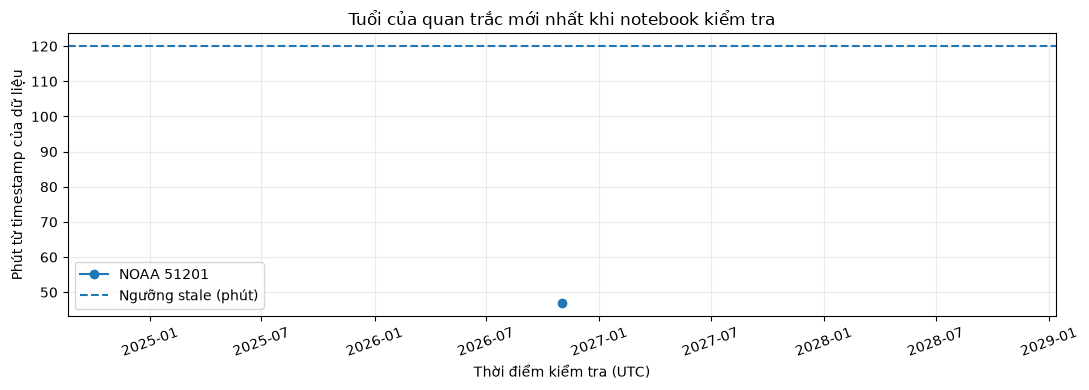

In [12]:
# Biểu đồ độ cũ của timestamp qua mỗi lần kiểm tra; loại dữ liệu mô hình tách biệt.
import matplotlib.pyplot as plt

obs = history_df[(history_df["data_type"] == "observation") &
                 (history_df["status"] == "ok")].copy()
if not obs.empty:
    obs["checked_at"] = pd.to_datetime(obs["poll_started_utc"], utc=True)
    fig, ax = plt.subplots(figsize=(11, 4))
    for name, group in obs.groupby("source"):
        ax.plot(group["checked_at"], group["age_minutes"], marker="o", label=name)
    ax.axhline(MAX_OBSERVATION_AGE_MIN, linestyle="--", label="Ngưỡng stale (phút)")
    ax.set(title="Tuổi của quan trắc mới nhất khi notebook kiểm tra",
           xlabel="Thời điểm kiểm tra (UTC)", ylabel="Phút từ timestamp của dữ liệu")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()
else:
    print("Chưa có quan trắc thành công để vẽ biểu đồ.")

## 10. Cách đọc kết quả và giới hạn

| Trường | Ý nghĩa |
|---|---|
| `data_time_utc` | CDIP/NOAA: timestamp số đo; Open-Meteo: giờ hiệu lực mô hình |
| `fetched_at_utc` | Giờ notebook nhận xong phản hồi HTTP |
| `age_minutes` | Tuổi timestamp so với giờ gọi, **không** phải SLA công bố |
| `change` | `INITIAL` (lần đầu thấy), `NEW` (timestamp đổi), `SAME` (chưa đổi), `ERROR` |
| `selected` | Nguồn được chọn theo ưu tiên và ngưỡng độ mới |
| `time_type` | Cột Open-Meteo: `PAST`, `CURRENT_HOUR` hoặc `FORECAST` |

**Chế độ 30 phút:** nếu phao phát hành bản ghi sau thời điểm vừa kiểm tra, notebook chỉ phát hiện ở mốc kế tiếp. Polling 30 phút tiết kiệm request nhưng **không đạt mục tiêu phát hiện trong 1 phút**; muốn kiểm tra tốc độ công bố nên dùng thử nghiệm ngắn với lịch nhanh hơn và tuân thủ giới hạn nguồn.

**Nguồn Open-Meteo:** giá trị tương lai chỉ là dự báo mô hình, không phải sóng đã đo tại trạm Waimea. **CDIP ↔ NOAA:** hai hệ thống cùng lấy một phao, timestamp có thể đại diện mốc khác nhau trong chu kỳ đo.


## 11. Những điều cần lưu ý khi đọc log thực tế

- Nếu CDIP báo `HTTP 403`, coi đây là lỗi quyền truy cập ở endpoint đó, **không có timestamp quan trắc**. NOAA vẫn có thể được chọn. Không tự suy đoán 403 là do thiếu API key hoặc bắt buộc phải dùng proxy.
- `data_time_utc` của NOAA là giờ gắn với bản ghi quan trắc; `age_minutes` là tuổi bản ghi tại thời điểm tải, **không chứng minh chính xác độ trễ công bố**.
- `current.time` của Open-Meteo là mốc mô hình, có thể là `07:45 UTC`, không phải mốc đo phao.
- Chỉ khi `MONITOR_ENABLED = True` và đã có từ 2 chu kỳ trở lên mới kiểm chứng được việc `change = NEW` hoặc `SAME`.
- Giờ hiển thị Việt Nam và Hawaii được chuyển từ UTC; với nguồn lỗi, các cột giờ được để trống thay vì gây lỗi.
